# UTS Graf Sains Data
- Nama :Rafly Anugrah Syahputra
- NIM :23031554195
- Kelas :Graf Sains Data 2023 A

In [1]:
import os
import math
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from neo4j import GraphDatabase
from tqdm import tqdm
from IPython.display import display

SEED = 42
BATCH = 20000
SRC = "archive/events.csv"
OUT = "data/events_filtered.csv"
DB = os.getenv("NEO4J_DATABASE", "neo4j")
DATASET = "uts_retailrocket_20150722_20150806"
driver = GraphDatabase.driver(
    os.getenv("NEO4J_URI", "neo4j://localhost:7687"),
    auth=(os.getenv("NEO4J_USER", "neo4j"), os.getenv("NEO4J_PASSWORD", "password123")))
driver.verify_connectivity()
session = driver.session(database=DB)
print("Terhubung ke database", DB)

Terhubung ke database neo4j


## 1. Tugas Pendahuluan

### Pertanyaan Checkpoint

**1. Apa nama database yang digunakan pada tutorial ini?**
Database bernama `neo4j`, ditentukan lewat `driver.session(database="neo4j")` atau `database_="neo4j"`.

**2. Akses lain untuk mengelola database lain dalam satu instance:**
- **Administrasi (DDL) lewat database `system`:** `SHOW DATABASES`, `CREATE DATABASE <nama>`, `START DATABASE <nama>`, `STOP DATABASE <nama>`, `DROP DATABASE <nama>`. Klausa `USE <nama>` hanya tersedia di edisi Enterprise.
- **Neo4j Browser / `cypher-shell`:** `:use <nama>`, misalnya `:use system`.
- **Driver Python:** `driver.session(database="<nama>")` atau `driver.execute_query(..., database_="<nama>")`.

**3. Jenis graf pertemanan yang dibuat:**
Graf berarah dan tidak berbobot dengan satu jenis simpul (`Person`) dan satu jenis relasi (`KNOWS`).

### Reset database

```cypher
MATCH (n) DETACH DELETE n;
```

> **Peringatan:** perintah ini menghapus seluruh isi database, jadi jangan dijalankan di database bersama. Sel di bawah hanya membuat simpul contoh berlabel `UTSDemo` lalu menghapus simpul berlabel itu saja.

In [2]:
session.run("""
UNWIND ['Guinevere', 'Lancelot', 'Merlin'] AS name
MERGE (a:Person:UTSDemo {name: 'Arthur'})
MERGE (b:Person:UTSDemo {name: name})
MERGE (a)-[:KNOWS]->(b)
""").consume()
display(pd.DataFrame(session.run(
    "MATCH (:Person:UTSDemo {name:'Arthur'})-[:KNOWS]->(f) RETURN f.name AS teman ORDER BY teman").data()))
session.run("MATCH (n:UTSDemo) DETACH DELETE n").consume()

,teman
0,Guinevere
1,Lancelot
2,Merlin


## 1.3 Impor Data RetailRocket ke Neo4j

Sumber data: Roman Zykov. File sudah ada di `archive/events.csv`, jadi tidak perlu diunduh lagi. Sel berikut memeriksa lokasi file dan memastikan kolom `timestamp`, `visitorid`, `event`, `itemid`, dan `transactionid` tersedia.

Koneksi dibuat pada sel inisialisasi ke database `neo4j` (bisa diganti lewat `NEO4J_DATABASE`). Impor ke Neo4j dilakukan setelah data difilter, dan hanya data periode training yang dimasukkan.

In [3]:
csv_file_path = Path(SRC)
if not csv_file_path.is_file():
    raise FileNotFoundError(f"File data tidak ditemukan: {csv_file_path.resolve()}")

columns = pd.read_csv(csv_file_path, nrows=0).columns.tolist()
required_columns = {"timestamp", "visitorid", "event", "itemid", "transactionid"}
missing_columns = required_columns.difference(columns)
if missing_columns:
    raise ValueError(f"Kolom CSV tidak lengkap: {sorted(missing_columns)}")

print(f"File data terdeteksi: {csv_file_path}")
display(pd.DataFrame({"Kolom CSV": columns}))

File data terdeteksi: archive/events.csv


,Kolom CSV
0,timestamp
1,visitorid
2,event
3,itemid
4,transactionid


## 2.1.1–2.1.2 Periode dan Filter Data

| Fold | Periode | Fungsi |
|---|---|---|
| P1 | 22 Juli – 5 Agustus 2015 | training |
| P2 | 6 – 19 Agustus 2015 | testing |

Kedua periode berurutan tanpa jeda dan berpindah pada **6 Agustus 2015 pukul 00.00 UTC**. Batas akhir tiap periode tidak ikut dihitung, jadi tidak ada event yang masuk ke dua fold. Kombinasi periode ini sudah dikonfirmasi berbeda dengan teman sekelas.

Setelah sel filter dijalankan, P1 berisi 333.738 event dan P2 berisi 248.110 event (total 581.848 baris). Pada kedua fold, `view` mendominasi, sedangkan `transaction` hanya sebagian kecil.

In [4]:
P1 = ("2015-07-22 00:00:00", "2015-08-06 00:00:00")
P2 = (P1[1], "2015-08-20 00:00:00")
to_ms = lambda s: int(pd.Timestamp(s, tz="UTC").timestamp() * 1000)
assert to_ms(P1[0]) < to_ms(P1[1]) == to_ms(P2[0]) < to_ms(P2[1])

In [5]:
ev = pd.read_csv(SRC)
assert not ev[["timestamp", "visitorid", "itemid", "event"]].isna().any().any()
assert set(ev.event.unique()) <= {"view", "addtocart", "transaction"}
ev["transactionid"] = ev.transactionid.astype("Int64")
m1 = ev.timestamp.between(to_ms(P1[0]), to_ms(P1[1]), inclusive="left")
m2 = ev.timestamp.between(to_ms(P2[0]), to_ms(P2[1]), inclusive="left")
flt = ev[m1 | m2].copy()
flt["fold"] = np.where(m1.loc[flt.index], "train", "test")
flt["event_id"] = flt.index  # ID baris sumber untuk mencegah event ganda saat impor ulang.
Path("data").mkdir(exist_ok=True)
flt.to_csv(OUT, index=False)
train = flt[flt.fold == "train"].copy()
test = flt[flt.fold == "test"].copy()
assert len(train) and len(test) and train.timestamp.max() < test.timestamp.min()
display(flt.groupby(["fold", "event"]).size().unstack(fill_value=0))
print("Hasil filter:", len(flt), "baris, disimpan ke", OUT)
del ev

event,addtocart,transaction,view
fold,,,
test,6591,1970,239549
train,8557,2886,322295


Hasil filter: 581848 baris, disimpan ke data/events_filtered.csv


### Impor ke Neo4j

Hanya P1 yang diimpor, sedangkan P2 disimpan untuk evaluasi. Visitor terhubung ke item lewat relasi `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`.

- `UNWIND` membaca data per batch.
- `MERGE` mencegah simpul dan relasi ganda.
- `FOREACH` memilih jenis relasi sesuai event.
- Properti `dataset` menandai relasi milik pekerjaan ini, sehingga isi database lain tidak ikut terhapus. Relasi bertanda ini dibangun ulang dari CSV setiap Run All.

In [6]:
while True:
    deleted = session.run("""
        MATCH ()-[r {dataset:$dataset}]->()
        WITH r LIMIT $batch DELETE r RETURN count(*) AS n
    """, dataset=DATASET, batch=BATCH).single()["n"]
    if deleted == 0:
        break
session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE").consume()
session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE").consume()
IMPORT_Q = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
  MERGE (v)-[r:VIEWED {dataset: $dataset, eventId: row.event_id}]->(i)
  SET r.timestamp = row.timestamp)
FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
  MERGE (v)-[r:ADDED_TO_CART {dataset: $dataset, eventId: row.event_id}]->(i)
  SET r.timestamp = row.timestamp)
FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
  MERGE (v)-[r:BOUGHT {dataset: $dataset, eventId: row.event_id}]->(i)
  SET r.timestamp = row.timestamp, r.transactionId = row.transactionid)
"""
for start in tqdm(range(0, len(train), BATCH), desc="Impor P1"):
    chunk = train.iloc[start:start + BATCH]
    records = chunk.astype(object).where(chunk.notna(), None).to_dict("records")
    session.execute_write(lambda tx: tx.run(IMPORT_Q, batch=records, dataset=DATASET).consume())


Impor P1:   0%|                                                                           | 0/17 [00:00<?, ?it/s]


Impor P1:   6%|███▉                                                               | 1/17 [00:18<05:02, 18.90s/it]


Impor P1:  12%|███████▉                                                           | 2/17 [00:28<03:23, 13.55s/it]


Impor P1:  18%|███████████▊                                                       | 3/17 [00:33<02:13,  9.54s/it]


Impor P1:  24%|███████████████▊                                                   | 4/17 [00:38<01:39,  7.63s/it]

...


Impor P1:  82%|██████████████████████████████████████████████████████▎           | 14/17 [01:18<00:10,  3.52s/it]


Impor P1:  88%|██████████████████████████████████████████████████████████▏       | 15/17 [01:22<00:06,  3.38s/it]


Impor P1:  94%|██████████████████████████████████████████████████████████████    | 16/17 [01:25<00:03,  3.32s/it]


Impor P1: 100%|██████████████████████████████████████████████████████████████████| 17/17 [01:27<00:00,  2.95s/it]


Impor P1: 100%|██████████████████████████████████████████████████████████████████| 17/17 [01:27<00:00,  5.13s/it]

## 2.1.3 Komposisi Subgraph

Query pertama mengambil kedua ujung relasi, `DISTINCT` membuat tiap simpul dihitung sekali, lalu `count(*)` menghitung per label. Query kedua menghitung jumlah relasi per jenis.

In [7]:
q_nodes = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT {dataset:$dataset}]->(i:Item)
UNWIND [v, i] AS n WITH DISTINCT n
RETURN labels(n)[0] AS jenis, count(*) AS jumlah ORDER BY jenis
"""
q_rels = """
MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT {dataset:$dataset}]->()
RETURN type(r) AS jenis, count(*) AS jumlah ORDER BY jenis
"""
nodes = pd.DataFrame(session.run(q_nodes, dataset=DATASET).data())
rels = pd.DataFrame(session.run(q_rels, dataset=DATASET).data())
display(nodes); display(rels)
assert rels.jumlah.sum() == len(train)
assert nodes.set_index("jenis").loc["Visitor", "jumlah"] == train.visitorid.nunique()
assert nodes.set_index("jenis").loc["Item", "jumlah"] == train.itemid.nunique()

,jenis,jumlah
0,Item,83501
1,Visitor,183787


,jenis,jumlah
0,ADDED_TO_CART,8557
1,BOUGHT,2886
2,VIEWED,322295


**Interpretasi.** Training berisi 183.787 visitor dan 83.501 item dengan 333.738 relasi, sama dengan jumlah baris P1, sehingga tidak ada event yang hilang atau ganda saat impor. Sebagian besar relasi berupa `VIEWED` (96,6%), sedangkan `ADDED_TO_CART` 2,6% dan `BOUGHT` 0,9%. Rata-rata hanya sekitar 1,8 relasi per visitor, sehingga kebanyakan pengunjung hanya berinteraksi sekali.

## 2.1.4–2.1.5 VSM User dan Item, serta Proyeksi

Matriks `B` berukuran user × item dengan bobot view = 1, addtocart = 3, transaction = 5. Bila pasangan user–item muncul berulang, diambil bobot terbesar. Bobot ini asumsi tentang kekuatan minat, dan nilai nol berarti belum ada interaksi.

- **Vektor user:** baris `B` (dimensi = jumlah item).
- **Vektor item:** baris `Bᵀ` (dimensi = jumlah user).
- **Proyeksi User:** dua user terhubung jika mengakses item yang sama.
- **Proyeksi Item:** dua item terhubung jika diakses user yang sama.

Gambar hanya menampilkan 12 simpul berderajat terbesar beserta sisi di antaranya, karena seluruh graf (183.787 user dan 83.501 item) terlalu besar untuk dibaca. Label simpul adalah ID asli, dan semua sisi digambar sama tebal sehingga tidak menunjukkan bobot.

In [8]:
train["w"] = train.event.map({"view": 1, "addtocart": 3, "transaction": 5})
agg = train.groupby(["visitorid", "itemid"], as_index=False).w.max()
u_ids = np.sort(agg.visitorid.unique())
i_ids = np.sort(agg.itemid.unique())
u_idx = {v: k for k, v in enumerate(u_ids)}
i_idx = {v: k for k, v in enumerate(i_ids)}
B = sp.csr_matrix((agg.w.astype(float), (agg.visitorid.map(u_idx), agg.itemid.map(i_idx))),
                  shape=(len(u_ids), len(i_ids)))
report = []
for name, M in [("User", B), ("Item", B.T)]:
    report.append({"VSM": name, "shape": M.shape, "dimensi vektor": M.shape[1],
                   "nilai bukan nol": M.nnz, "sparsity (%)": 100 * (1 - M.nnz / np.prod(M.shape))})
display(pd.DataFrame(report))

,VSM,shape,dimensi vektor,nilai bukan nol,sparsity (%)
0,User,"(183787, 83501)",83501,266008,99.998267
1,Item,"(83501, 183787)",183787,266008,99.998267


**Interpretasi.** Sparsity 99,998% berarti hampir seluruh pasangan user–item tidak berinteraksi. Dari 333.738 event training hanya tersisa 266.008 pasangan unik, sehingga ada user yang berinteraksi dengan item yang sama lebih dari sekali. Dengan data sejarang ini, similarity mudah bernilai nol, dan representasi sparse wajib dipakai.

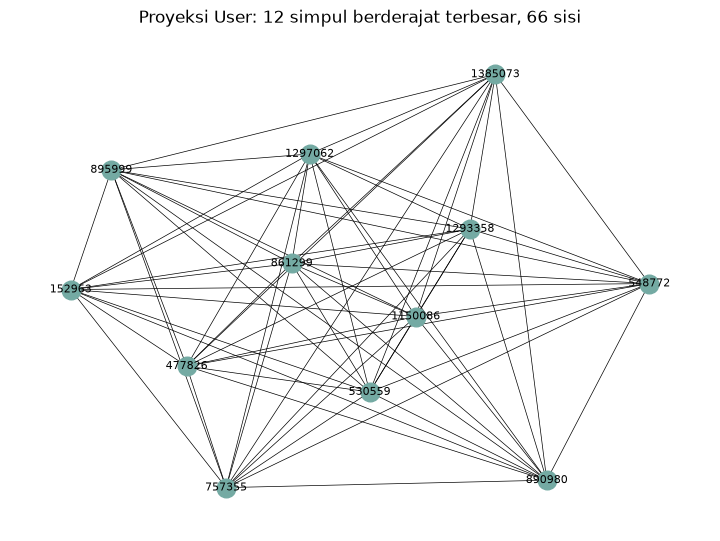

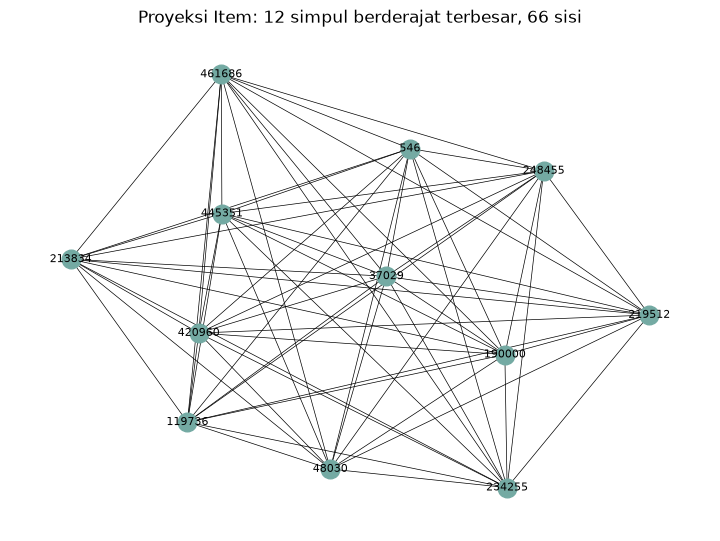

In [9]:
def plot_projection(P, ids, title, n=12):
    top = np.lexsort((ids, -np.diff(P.indptr)))[:n]
    G = nx.from_scipy_sparse_array(P[top][:, top])
    G = nx.relabel_nodes(G, {j: int(ids[top[j]]) for j in range(len(top))})
    plt.figure(figsize=(7, 5))
    nx.draw(G, nx.spring_layout(G, seed=SEED), with_labels=True,
            node_size=180, font_size=8, width=0.5, node_color="#74aaa3")
    plt.title(f"{title}: {len(top)} simpul berderajat terbesar, {G.number_of_edges()} sisi")
    plt.show()

A = B.copy(); A.data[:] = 1.0
P_user = (A @ A.T).tocsr()
P_item = (A.T @ A).tocsr()
for P in [P_user, P_item]:
    P.setdiag(0); P.eliminate_zeros()
plot_projection(P_user, u_ids, "Proyeksi User")
plot_projection(P_item, i_ids, "Proyeksi Item")

**Interpretasi.** Kedua cuplikan berisi 66 sisi, yaitu 12×11/2, sehingga 12 simpul teratas saling terhubung semuanya (klik). Artinya simpul berderajat tertinggi berkumpul di inti graf: user yang paling aktif saling berbagi item, dan item yang paling populer sama-sama diakses user yang sama. Gambar ini hanya inti graf, bukan gambaran seluruhnya, karena sebagian besar simpul lain jarang terhubung.

## 2.1.6 Pemilihan Proyeksi

Dengan U = 183.787 user dan I = 83.501 item, proyeksi User berukuran U×U dan proyeksi Item I×I. Bila disimpan sebagai matriks padat `float64`, kebutuhan memorinya sekitar 251,66 GiB (User) dan 51,95 GiB (Item), sehingga keduanya harus disimpan sebagai matriks sparse (CSR).

**Biaya komputasi.** Perkalian padat berorde O(U²I) untuk User dan O(I²U) untuk Item. Pada matriks sparse, biayanya bergantung pada pola interaksi. Jumlah kontribusi pasangan lewat tetangga bersama dihitung dengan Σ d(d−1)/2, yaitu 2.168.827 (User) dan 1.806.354 (Item). Angka ini bukan jumlah sisi unik, sebab pasangan yang punya beberapa tetangga bersama terhitung berulang.

**Kepadatan** (2E / [N(N−1)]): User 0,01245% dan Item 0,04948%. Secara relatif, proyeksi Item lebih padat walaupun jumlah sisinya lebih sedikit.

**Keputusan.** Saya memilih proyeksi **Item** karena memori CSR-nya sekitar 18,46% lebih kecil dan rekomendasi yang dibutuhkan memang berbasis item. Kekurangannya, 48,68% item terisolasi (user: 16,16%). Klaim bahwa Item lebih akurat belum bisa dibuat karena tidak dibandingkan dengan rekomendasi berbasis user.

In [10]:
comparison = []
for name, P in [("User", P_user), ("Item", P_item)]:
    comparison.append({"proyeksi": name, "simpul": P.shape[0], "sisi": P.nnz // 2,
        "terisolasi (%)": 100 * np.mean(np.diff(P.indptr) == 0),
        "memori CSR (MiB)": (P.data.nbytes + P.indices.nbytes + P.indptr.nbytes) / 2**20})
display(pd.DataFrame(comparison))
del A, P_user, P_item, P

,proyeksi,simpul,sisi,terisolasi (%),memori CSR (MiB)
0,User,183787,2101923,16.162188,48.810295
1,Item,83501,1724870,48.683249,39.797676


**Interpretasi.** Proyeksi Item lebih hemat memori (39,8 MiB berbanding 48,8 MiB) karena jumlah item lebih sedikit daripada user. Akan tetapi, hampir separuh item (48,7%) tidak terhubung ke item lain, artinya item tersebut hanya diakses oleh user yang tidak mengakses item lain. Item seperti ini tidak bisa mendapat rekomendasi dari similarity (*cold start*).

## 2.1.7 Cosine Similarity dan Lima Item Terdekat

$$\text{sim}(i,j)=\frac{b_i\cdot b_j}{\lVert b_i\rVert\,\lVert b_j\rVert}$$

Vektor $b_i$ adalah kolom item pada `B` (data P1). Item acuan adalah item yang diakses paling banyak user (jika seri, dipilih ID terkecil). Lima skor tertinggi ditulis sebagai relasi `SIMILAR_TO` untuk menjawab soal 7a–b. Similarity seluruh item tetap disimpan di Python untuk keperluan rekomendasi.

In [11]:
Bi = normalize(B.T.tocsr())
S = (Bi @ Bi.T).tocsr()
S.setdiag(0); S.eliminate_zeros()

def topk_row(S, r, k):
    start, end = S.indptr[r:r + 2]
    idx, val = S.indices[start:end], S.data[start:end]
    order = np.lexsort((idx, -val))[:k]
    return idx[order], val[order]

ref_idx = int(np.lexsort((i_ids, -np.diff(B.tocsc().indptr)))[0])
ref_item = int(i_ids[ref_idx])
idx, scores = topk_row(S, ref_idx, 5)
sim_rows = [{"item": int(i_ids[j]), "score": float(s)} for j, s in zip(idx, scores)]
assert len(sim_rows) == 5 and all(0 < r["score"] <= 1 + 1e-12 for r in sim_rows)
print("Item acuan:", ref_item)

Item acuan: 149275


In [12]:
q_before = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT {dataset:$dataset}]->(:Item {itemId:$ref})
RETURN v.visitorId AS visitor, collect(DISTINCT type(r)) AS jenis
ORDER BY visitor LIMIT 12
"""
before = session.run(q_before, dataset=DATASET, ref=ref_item).data()
WRITE_Q = """
UNWIND $rows AS row
MATCH (a:Item {itemId:$ref}), (b:Item {itemId:row.item})
MERGE (a)-[r:SIMILAR_TO {dataset:$dataset}]->(b) SET r.score = row.score
"""
session.execute_write(lambda tx: tx.run(WRITE_Q, rows=sim_rows, ref=ref_item, dataset=DATASET).consume())
q_top5 = """
MATCH (:Item {itemId:$ref})-[r:SIMILAR_TO {dataset:$dataset}]->(b:Item)
RETURN b.itemId AS itemId, r.score AS similarity
ORDER BY similarity DESC, itemId LIMIT 5
"""
top5 = pd.DataFrame(session.run(q_top5, dataset=DATASET, ref=ref_item).data())
display(top5)
assert top5.itemId.tolist() == [r["item"] for r in sim_rows]
assert np.allclose(top5.similarity, [r["score"] for r in sim_rows])

,itemId,similarity
0,33,0.045835
1,53394,0.045835
2,115667,0.045835
3,122509,0.045835
4,235200,0.043214


**Interpretasi.** Skor cosine lima item terdekat sangat kecil (0,043–0,046), dan tiga di antaranya sama persis. Item acuan `149275` diakses banyak user, sedangkan tetangganya hanya berbagi sedikit user dengannya, sehingga kemiripannya rendah walaupun peringkatnya tertinggi. Dalam data seperti ini, urutan tetangga lebih bermakna daripada nilai skornya.

## 2.1.8 Graf Sebelum dan Sesudah Similarity

Panel kiri memakai hasil `q_before`, yaitu graf sebelum relasi similarity ditulis. Panel kanan menambahkan lima relasi dari `q_top5`. Huruf V menandai Visitor dan I menandai Item. Satu garis Visitor–Item merangkum semua jenis interaksi pasangan tersebut.

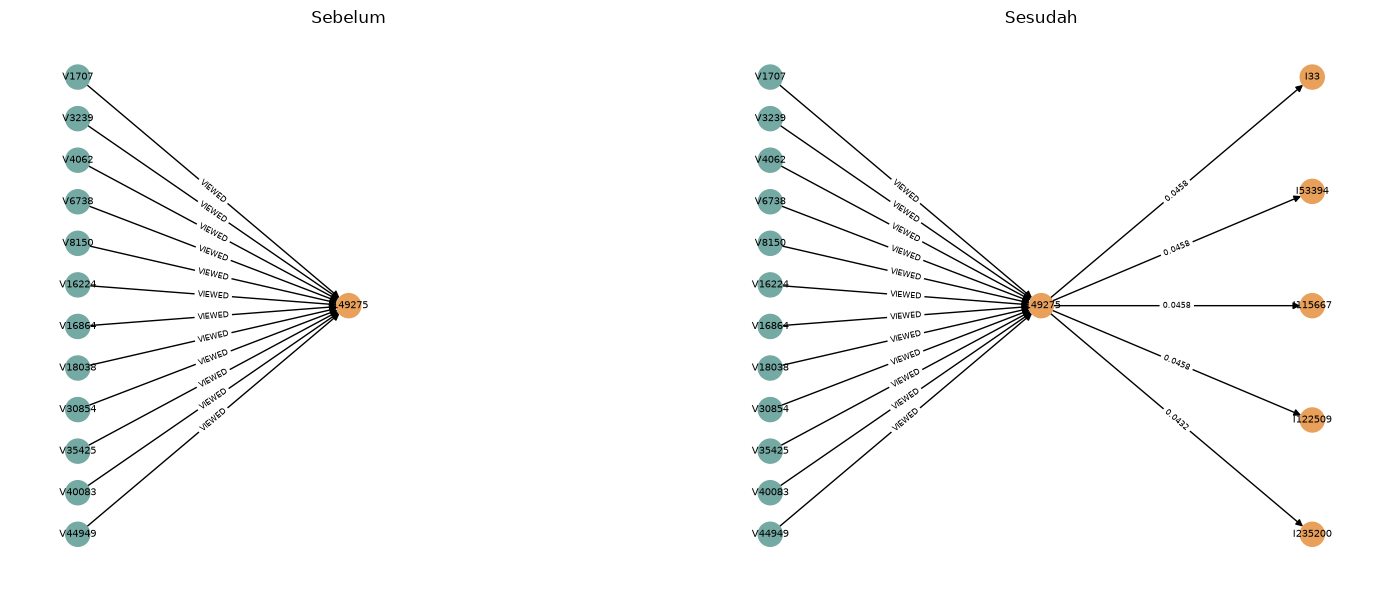

In [13]:
G1 = nx.DiGraph()
for r in before:
    G1.add_edge(f"V{r['visitor']}", f"I{ref_item}", label=", ".join(r["jenis"]))
G2 = G1.copy()
for r in top5.itertuples():
    G2.add_edge(f"I{ref_item}", f"I{r.itemId}", label=f"{r.similarity:.4f}")
visitors = list(G1.predecessors(f"I{ref_item}"))
items = [f"I{i}" for i in top5.itemId]
pos = {f"I{ref_item}": (0, 0)}
pos.update({v: (-1, y) for v, y in zip(visitors, np.linspace(1, -1, len(visitors)))})
pos.update({i: (1, y) for i, y in zip(items, np.linspace(1, -1, len(items)))})
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, G, title in [(axes[0], G1, "Sebelum"), (axes[1], G2, "Sesudah")]:
    nx.draw(G, pos, ax=ax, with_labels=True, node_size=300, font_size=7,
            node_color=["#e8a05a" if n.startswith("I") else "#74aaa3" for n in G])
    nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels=nx.get_edge_attributes(G, "label"), font_size=6)
    ax.set_title(title); ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.2, 1.2)
plt.tight_layout(); plt.show()
assert session.run("MATCH ()-[r {dataset:$dataset}]->() WHERE type(r)='SIMILAR_TO' RETURN count(*) AS n",
                   dataset=DATASET).single()["n"] == 5
assert pd.DataFrame(session.run(q_rels, dataset=DATASET).data()).equals(rels)

## 2.2.1 Rekomendasi KNN (k = 5)

User dipilih acak (seed 42) dari user yang muncul di P1 dan P2 serta punya minimal dua item di P1. P2 tidak dipakai untuk menghitung similarity.

KNN yang dipakai berbasis item: untuk tiap item pada riwayat user diambil lima tetangga terdekat. Skor kandidat adalah jumlah dari `bobot interaksi × similarity`. Item yang sudah diakses di P1 dikeluarkan, dan tiga kandidat berskor tertinggi menjadi iklan.

In [14]:
K = 5
test_items = test.groupby("visitorid").itemid.apply(set).to_dict()
cand = [u for u in u_ids if B[u_idx[u]].nnz >= 2 and u in test_items]
assert cand, "Tidak ada user yang memenuhi syarat."
user = int(np.random.default_rng(SEED).choice(cand))

def recommend(u, topn=3, k=K):
    row = B[u_idx[u]]
    scores = {}
    for ii, weight in zip(row.indices, row.data):
        idx, sim = topk_row(S, ii, k)
        for j, value in zip(idx, sim):
            scores[j] = scores.get(j, 0.0) + weight * value
    seen = set(row.indices)
    ranked = [(int(i_ids[j]), float(score)) for j, score in scores.items() if j not in seen]
    return sorted(ranked, key=lambda r: (-r[1], r[0]))[:topn]

rec3 = recommend(user)
rec_ids = [i for i, _ in rec3]
assert len(rec3) == 3 and not set(rec_ids) & set(i_ids[B[u_idx[user]].indices])
print("User:", user, "| Riwayat P1:", sorted(i_ids[B[u_idx[user]].indices].tolist()))
display(pd.DataFrame(rec3, columns=["item iklan", "skor"], index=[1, 2, 3]).rename_axis("peringkat"))

User: 132417 | Riwayat P1: [68613, 101983, 257242, 342330]


,item iklan,skor
peringkat,,
1,154491,0.707107
2,260942,0.707107
3,75790,0.500000


**Interpretasi.** User terpilih punya 4 item riwayat di P1, dan tiga iklan diambil dari tetangga item-item tersebut. Dua iklan teratas punya skor sama (0,7071), jadi urutannya ditentukan oleh ID yang lebih kecil. Skor yang kecil dan bernilai sama menunjukkan kandidat berasal dari sedikit sumber, bukan dari dukungan banyak item riwayat.

## 2.2.2 Hit@5 dan NDCG@5

Item relevan adalah semua item unik yang diakses user di P2, termasuk yang hanya dilihat. Yang dinilai adalah tiga item iklan dari bagian sebelumnya. Karena cutoff-nya 5 dan iklan hanya tiga, posisi 4–5 kosong dan tidak menambah skor.

- **Hit@5** = 1 bila ada iklan yang relevan, selain itu 0.
- **DCG@5** = Σ rel(r) / log₂(r+1).
- **IDCG@5** = DCG untuk urutan ideal dengan min(5, jumlah item relevan) item.
- **NDCG@5** = DCG@5 / IDCG@5.

In [15]:
def hit_at(recs, truth, n=5):
    return int(any(item in truth for item in recs[:n]))

def ndcg_at(recs, truth, n=5):
    dcg = sum(1 / math.log2(p + 2) for p, item in enumerate(recs[:n]) if item in truth)
    idcg = sum(1 / math.log2(p + 2) for p in range(min(len(truth), n)))
    return dcg / idcg if idcg else 0.0

truth = test_items[user]
print("Item pada P2:", sorted(truth))
print("Iklan yang cocok:", sorted(set(rec_ids) & truth))
display(pd.DataFrame({"Hit@5": [hit_at(rec_ids, truth)], "NDCG@5": [ndcg_at(rec_ids, truth)]}))
if not set(rec_ids) & truth:
    print("Tidak ada iklan yang muncul pada P2, sehingga Hit@5 dan NDCG@5 sama-sama 0.")
session.close()
driver.close()

Item pada P2: [267596]
Iklan yang cocok: []


,Hit@5,NDCG@5
0,0,0.0


Tidak ada iklan yang muncul pada P2, sehingga Hit@5 dan NDCG@5 sama-sama 0.


**Interpretasi.** User ini hanya membuka satu item di P2 (`267596`), dan item itu tidak masuk tiga iklan, jadi Hit@5 dan NDCG@5 bernilai 0. Hasil ini belum cukup untuk menilai kualitas model karena hanya memakai satu user. Penilaian yang layak perlu rata-rata Hit@5 dan NDCG@5 dari banyak user. Satu hal yang sudah terlihat: item yang akan dilihat user di P2 tidak selalu berdekatan dengan riwayat P1-nya.